# NGC 2403: recovering all radial kinematic fields

## Problem

Recover circular speed $V(R)$, intrinsic one-dimensional dispersion $s(R)$ and receding-side position angle $\phi(R)$ on **all41 radial knots** from a real neutral-hydrogen spectral image cube. These are radial physical fields of a projected gas disk, not scalar calibration estimates. Spatial beam mixing couples rotation gradients to apparent line width.

This notebook actively executes the complete cleaned reconstruction. Its comparison is a **qualified original-method estimate, not independent galaxy truth**. The original initialization copied41 entries from a40-element2D fit; ASAN established a heap overread. The qualified source only bounds that copy and retains the supplied unmatched-ring start. All41 rings remain fitted. The selected current-source configuration uses azimuthal normalization; it is not an unchanged numerical reproduction of every2015 paper default.


In [1]:
from pathlib import Path
import os,sys,time,json,platform,io,contextlib,importlib.util
import numpy as np
import scipy
import matplotlib
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src/main.py').is_file(): ROOT=ROOT.parent
assert (ROOT/'src/main.py').is_file()
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.preprocessing import search_mask,first_moment
from src.physics_model import cloud_cube,beam_kernel,beam_convolve,full_model
from src.main import run
from src import visualization as viz
with contextlib.redirect_stdout(io.StringIO()) as config_text: np.show_config()
environment=dict(executable=sys.executable,python=sys.version,platform=platform.platform(),numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__,backend=matplotlib.get_backend(),threads={k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']},numpy_configuration=config_text.getvalue())
(ROOT/'notebooks/reference_outputs/runtime_environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
print(json.dumps({k:v for k,v in environment.items() if k!='numpy_configuration'},indent=2))


{
  "executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]",
  "platform": "Windows-10-10.0.26200-SP0",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "inline",
  "threads": {
    "OMP_NUM_THREADS": "1",
    "OPENBLAS_NUM_THREADS": "1",
    "MKL_NUM_THREADS": "1"
  }
}


D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Lib\site-packages\numpy\__config__.py:155: UserWarning: Install `pyyaml` for better output
  warnings.warn("Install `pyyaml` for better output", stacklevel=1)


## Data

The input retains the entire native **62x150x150 float32** VLA cube:1,395,000 finite observed intensities in Jy/beam, including negative noise values. Native velocity centers are $289.610969-5.15286k$km/s for channel index $k=0,\ldots,61$. Image x/y angular steps are−/+16.00000038756arcsec. The Gaussian beam FWHM is59.3287870284 by58.6053617292arcsec at PA−79.446372986degrees.

The observation-only source detector uses the median/MAD noise estimate,4sigma detection and2.5sigma growth with the original extended adjacency. Its153243 selected voxels support the intensity-weighted velocity summary on13687 pixels. **Missing summary pixels are not removed from the unknown field or the full-cube residual.** The model center(77,77) is a fixed zero-based source assumption, distinct from the FITS one-based reference pixel(76,76).


Complete observed voxels: 1395000 detected voxels: 153243 velocity-summary support: 13687
Observation-only noise statistics: {'median': 6.816191307734698e-05, 'mad': 0.0003735983045771718, 'spread': 0.0005538984551094472, 'threshold': 0.0022837556898593903, 'growth_threshold': 0.0014529080362990499}


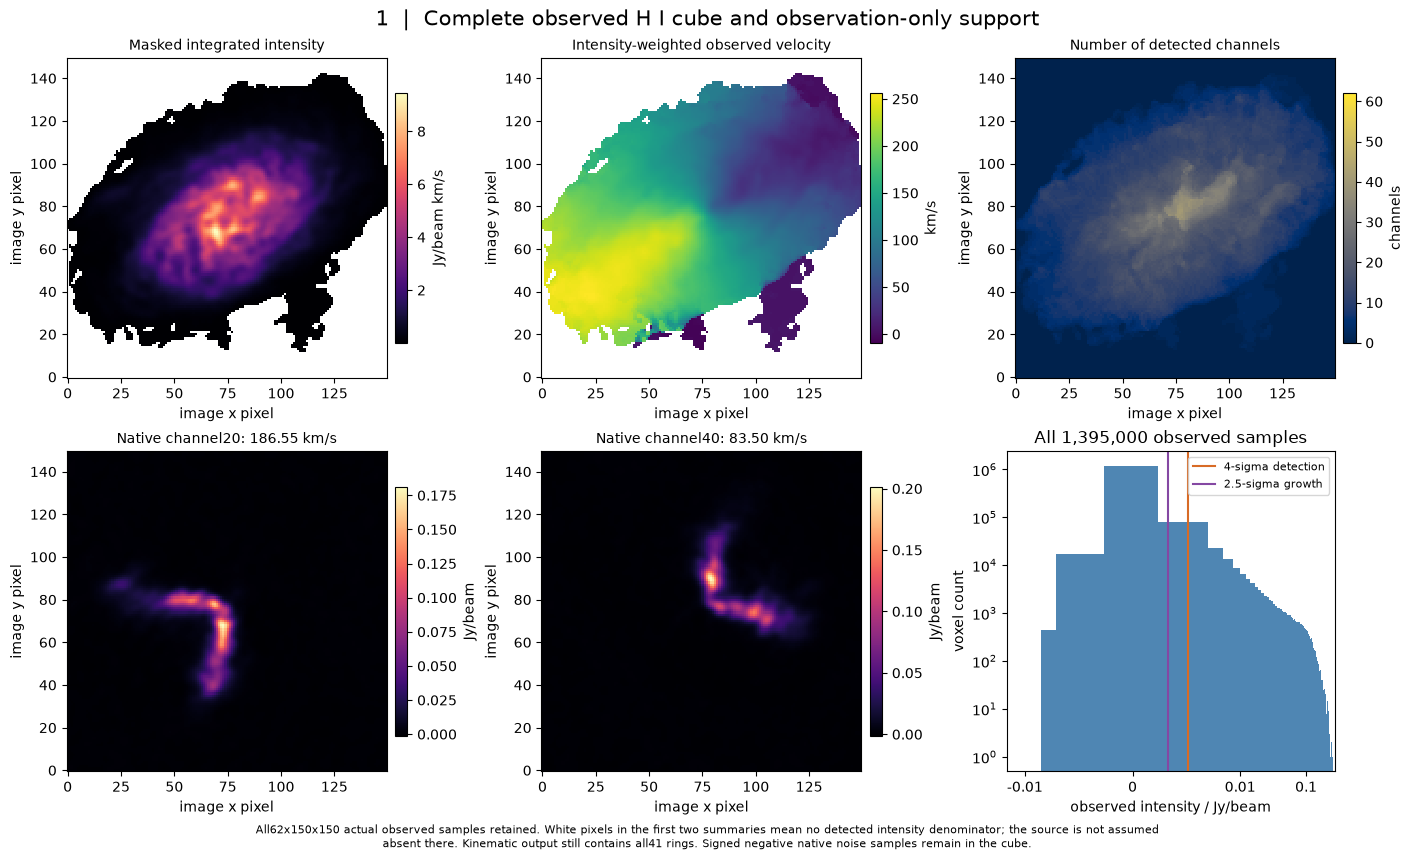

In [2]:
with np.load(ROOT/'data/raw_data.npz',allow_pickle=False) as archive: cube=archive['spectral_cube'][0]
mask,statistics=search_mask(cube)
moment=first_moment(cube,mask)
assert cube.shape==(62,150,150) and mask.sum()==153243
print('Complete observed voxels:',cube.size,'detected voxels:',int(mask.sum()),'velocity-summary support:',int(np.isfinite(moment).sum()))
print('Observation-only noise statistics:',statistics)
figure=viz.plot_data(cube,mask,moment,statistics)
display(figure);plt.close(figure)


## Physics

For disk-plane azimuth $\theta$, radius $R$ and height $z$, set $x_d=R\cos\theta$ and $y_d=R\sin\theta\cos i-z\sin i$, where inclination $i=60$degrees. The angular lengths use a common unit. The image-plane projection is

$$x_p=x_0+\frac{x_d\sin\phi-y_d\cos\phi}{\delta_x},\qquad
y_p=y_0+\frac{x_d\cos\phi+y_d\sin\phi}{\delta_y}.$$

Here $(x_0,y_0)=(77,77)$ and $(\delta_x,\delta_y)$ are the signed angular pixel steps. The line-of-sight velocity is

$$v=v_s+V(R)\cos\theta\sin i+\epsilon,\qquad
\epsilon\sim\mathcal N(0,s(R)^2+s_I^2),$$

where $v_s=132.8$km/s and instrumental standard deviation $s_I$ uses a one-channel Gaussian FWHM approximation. Channel binning remains an additional nearest-channel discretization. The source's inactive channel-box variance subtraction is not inserted into the selected model.

Cloud positions are uniform in annular area and azimuth, with normalized vertical density $\operatorname{sech}^2(z/z_0)/(2z_0)$ and $z_0=10$arcsec. Explicit Monte-Carlo quadrature projects those positions and builds spectral profiles, followed by the normalized elliptical Gaussian beam. The active cloud parameter is10, rather than the lower-level constructor's overridden1. Float32 assignments and source rounding conventions are preserved.

The next comparison isolates an actual captured inner-annulus case. It is a small **operator diagnostic**, not a replacement for the full bound observation. Original spatial/velocity variates are explicit inputs, so the deterministic operator comparison does not treat same-seed random output as a scientific quality test. Independent complete-source seeds and distributional checks address stochastic quality separately.


Conditional raw-operator max absolute difference: 0.0
Beam kernel sum: 1.0000000000000002 convolved max absolute difference: 0.0


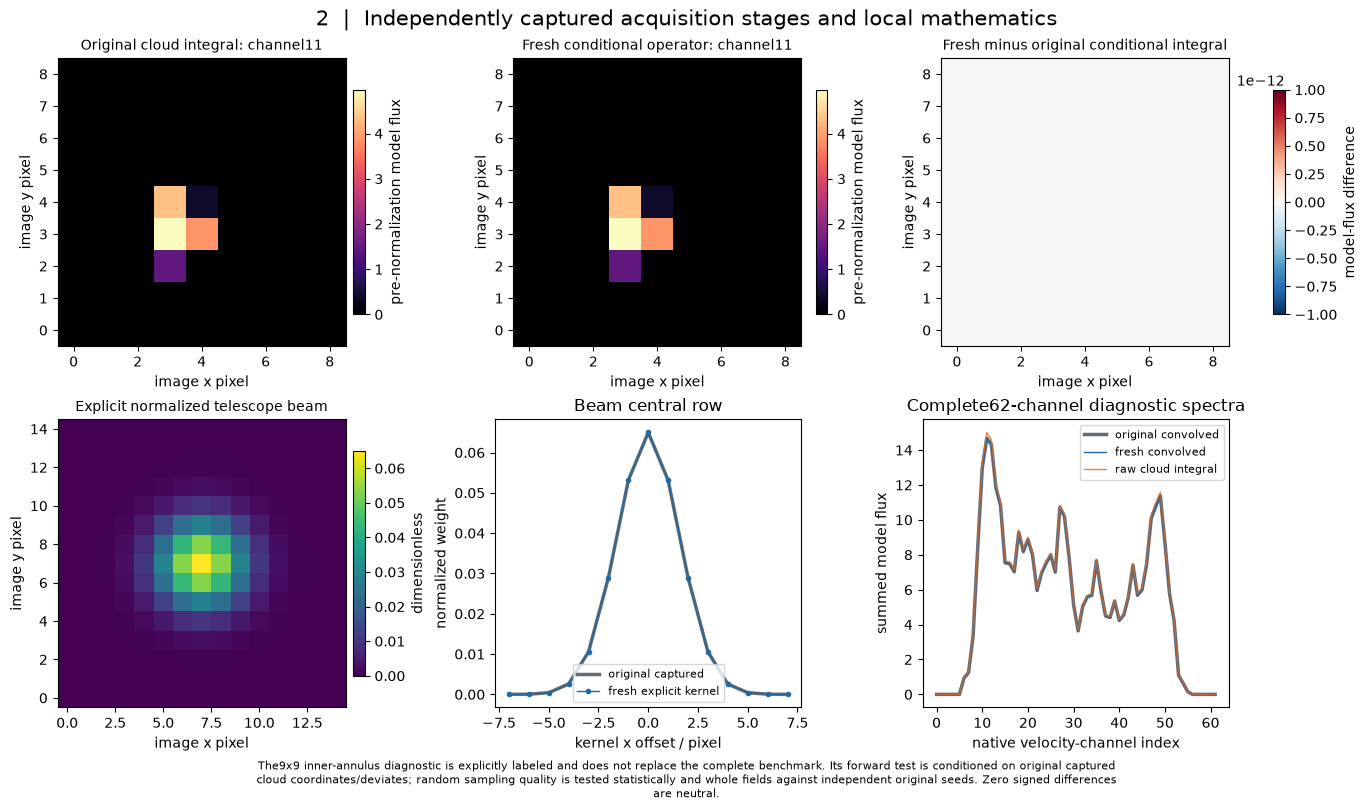

In [3]:
with np.load(ROOT/'test/fixtures/cloud_model_1.npz',allow_pickle=False) as case:
    original_raw=case['output_cube']
    fresh_raw=cloud_cube(case['input_internal_rings'],case['param_metadata'],quadrature=case['input_quadrature'])
with np.load(ROOT/'test/fixtures/convolution_1.npz',allow_pickle=False) as case:
    original_kernel=case['input_kernel']
    original_smoothed=case['output_cube']
fresh_kernel=beam_kernel()
fresh_smoothed=beam_convolve(fresh_raw,fresh_kernel)
print('Conditional raw-operator max absolute difference:',float(abs(fresh_raw-original_raw).max()))
print('Beam kernel sum:',float(fresh_kernel.sum()),'convolved max absolute difference:',float(abs(fresh_smoothed-original_smoothed).max()))
figure=viz.plot_operator(original_raw,fresh_raw,original_kernel,fresh_kernel,original_smoothed,fresh_smoothed)
display(figure);plt.close(figure)


## Method

The complete source method first initializes rotation and PA by fitting the intensity-weighted velocity map on40 native prepass rings. It uses analytic derivatives, scaled normal equations and the original damping/backtracking rules. The qualified copy maps only available values into the41-ring initialization, preserving the user start on the unmatched last ring and the first rotation start.

The3D inverse uses an explicitly implemented float32 downhill simplex for each annulus. It fits rotation,dispersion and PA, computes the source low-scatter median PA regularization, then refits both kinematic profiles with the angle fixed. The relative simplex objective spread stopping tolerance is0.001; the original reflection,expansion,contraction,shrink,tie and evaluation-count conventions remain intact.

Let $d$ denote observations, $m$ the unnormalized beam-convolved model, $b$ the observation-only mask and $\mathcal A$ the projected annulus over all channels. Its gain and selected objective are

$$\mu=\frac{\sum_{\mathcal A}bd}{\sum_{\mathcal A}m},\qquad
J=\left(1+\frac{N_b}{N_c}\right)
\frac{\sum_{\mathcal C}\cos^2\theta\,|\mu m-d_+|}{N_c-N_b}.$$

The counted set $\mathcal C$ includes mask-true or nonzero-model voxels; $N_c$ is its size and $N_b$ counts its mask-false members. The disk azimuth is $\theta$. Positive measurements retain their actual value in $d_+$; nonpositive measurements use the observation-derived noise standard deviation. Zero model sum gives gain zero. Cube scaling to maximum10 and source float32 accumulation order are preserved and reversed before returning physical fields.

**The next cell executes all41 rings in both fitting stages from raw_data.npz.** It reads no baseline or fitted reference to initialize or solve. Geometry-dependent random quadrature may be memoized; parameter fields,objective values and forward cubes are always freshly computed.


In [4]:
started=time.perf_counter()
def progress(stage,ring,field,result):
    if ring in [1,10,20,30,41]: print(f'Fresh stage{stage} ring{ring}/41: {field.tolist()}',flush=True)
fresh,diagnostics=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz',progress=progress)
reconstruction_seconds=time.perf_counter()-started
fresh_fields=np.column_stack([fresh[key][0] for key in ['rotation','dispersion','position_angle']])
fresh_model,fresh_profile=full_model(cube,diagnostics['mask'],fresh_fields)
spec=importlib.util.spec_from_file_location('independent_review_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
fresh_report,judge_code=judge.evaluate(ROOT/'output/reconstruction.npz')
assert judge_code==0 and fresh_report['passed'],fresh_report
np.savez_compressed(ROOT/'notebooks/reference_outputs/cleaned_measurements.npz',rotation=fresh['rotation'],dispersion=fresh['dispersion'],position_angle=fresh['position_angle'],initial=diagnostics['initial'][None],prepass=diagnostics['prepass_parameters'][None],stage_fields=diagnostics['stage_fields'][None],stage_losses=diagnostics['stage_losses'][None],stage_evaluations=diagnostics['stage_evaluations'][None],model=fresh_model[None],nuisance_profile=fresh_profile[None])
measurement=dict(role='Fresh active cleaned-code reconstruction and independent standalone scoring; not truth',reconstruction_seconds=reconstruction_seconds,metrics=fresh_report['metrics'],thresholds=fresh_report['thresholds'],seed=-1,source='public raw_data.npz only',environment='runtime_environment.json')
(ROOT/'notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps(measurement,indent=2),encoding='utf-8')
print('Active complete reconstruction seconds:',reconstruction_seconds)
print(json.dumps(fresh_report,indent=2))


Fresh stage1 ring1/41: [53.84151840209961, 17.917295455932617, 140.60171508789062]


Fresh stage1 ring10/41: [120.20817565917969, 13.665863990783691, 123.90972900390625]


Fresh stage1 ring20/41: [127.03558349609375, 10.921426773071289, 124.43315887451172]


Fresh stage1 ring30/41: [135.17471313476562, 11.730761528015137, 124.31263732910156]


Fresh stage1 ring41/41: [135.58401489257812, 13.143019676208496, 120.90045166015625]


...

Fresh stage2 ring10/41: [120.20817565917969, 13.665863990783691, 124.31263732910156]


Fresh stage2 ring20/41: [126.4267578125, 11.038691520690918, 124.31263732910156]


Fresh stage2 ring30/41: [134.28848266601562, 11.343186378479004, 124.31263732910156]


Fresh stage2 ring41/41: [135.23245239257812, 11.336380004882812, 124.31263732910156]


Active complete reconstruction seconds: 758.7620079999906
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "rotation_range_nrmse": 5.751376769671087e-08,
    "dispersion_range_nrmse": 0.0,
    "position_angle_wrapped_rms_deg": 0.0,
    "full_cube_rms_Jy_beam": 0.004572889593277305
  },
  "thresholds": {
    "rotation_range_nrmse": {
      "comparison": "<=",
      "boundary": 0.017034759657074735
    },
    "dispersion_range_nrmse": {
      "comparison": "<=",
      "boundary": 0.10383335124662954
    },
    "position_angle_wrapped_rms_deg": {
      "comparison": "<=",
      "boundary": 0.3988151550292969
    },
    "full_cube_rms_Jy_beam": {
      "comparison": "<=",
      "boundary": 0.005076774190082738
    }
  },
  "errors": [],
  "observation_consistency_evaluated": true
}


## Results

Only now are the separately identified qualified-original captures loaded for comparison. The baseline is a conditional estimate, not an independent measurement of galaxy kinematics. Independent source runs with ISEED−2 and−3 quantify reproducibility; their plotted range is **not a confidence interval**. The source-only thresholds were frozen before local extraction and are not narrowed because the chosen-source-stream result is close.

Rotation and dispersion are assessed separately by RMS error divided by each profile's own dynamic range. Position angle uses RMS wrapped degree differences, permitting equivalent whole turns. No amplitude fitting,constant-offset removal,registration or hidden crop is applied. The PA profile is constant after median regularization, so range-normalizing it would be undefined and is not used.


| Quantity | Fresh vs qualified original | Pass boundary |
|---|---:|---:|
| `rotation_range_nrmse` | 5.75137677e-08 | 0.0170347597 |
| `dispersion_range_nrmse` | 0 | 0.103833351 |
| `position_angle_wrapped_rms_deg` | 0 | 0.398815155 |
| `full_cube_rms_Jy_beam` | 0.00457288959 | 0.00507677419 |

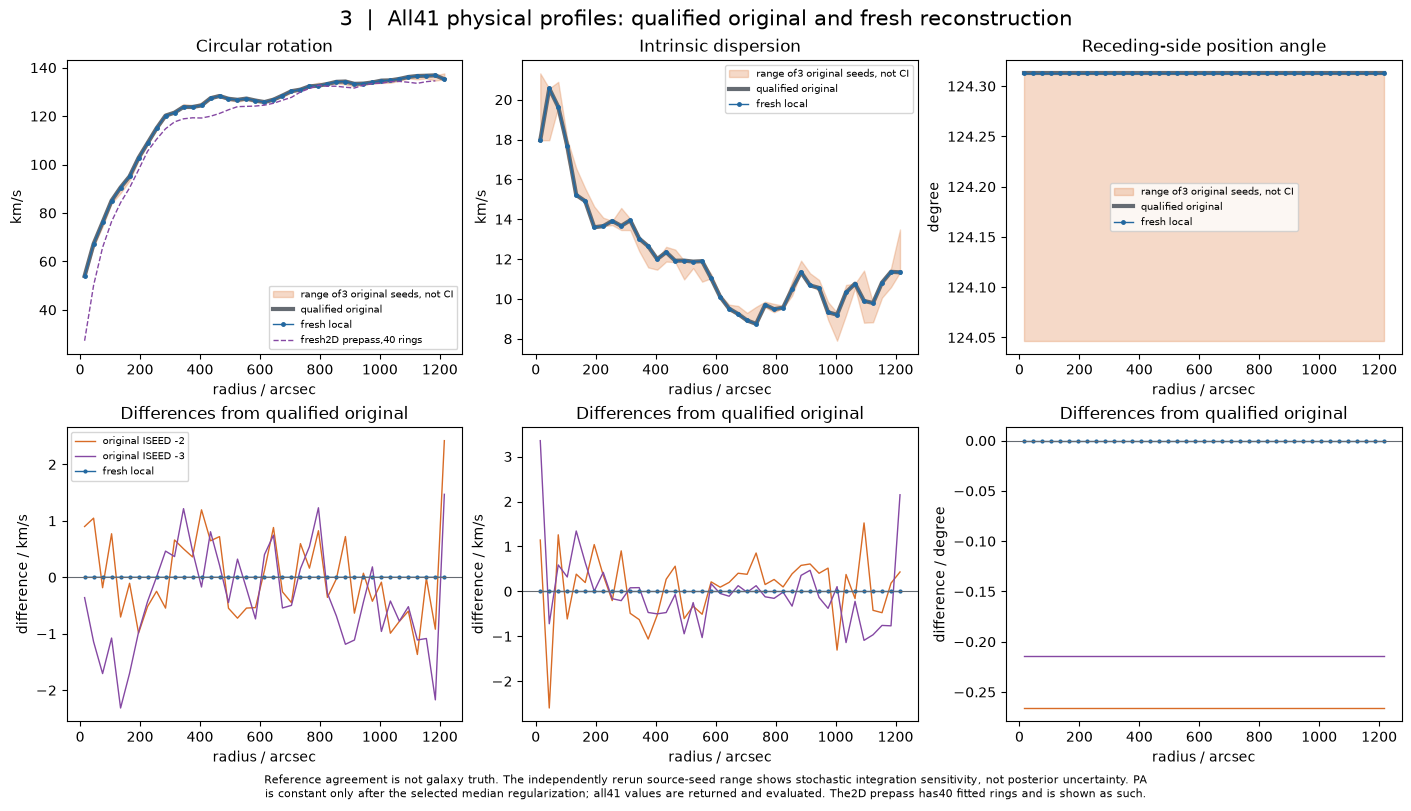

In [5]:
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as archive:
    original_fields=np.column_stack([archive[key][0] for key in ['rotation','dispersion','position_angle']])
with np.load(ROOT/'notebooks/reference_outputs/upstream_experiments.npz',allow_pickle=False) as archive:
    original_model=archive['source_model'][0]
    seed2=archive['source_seed2'][0];seed3=archive['source_seed3'][0]
    source_stage1=archive['source_stage1'][0]
rows=['| Quantity | Fresh vs qualified original | Pass boundary |','|---|---:|---:|']
for key,value in fresh_report['metrics'].items(): rows.append(f"| `{key}` | {value:.9g} | {fresh_report['thresholds'][key]['boundary']:.9g} |")
display(Markdown('\n'.join(rows)))
figure=viz.plot_fields(original_fields,fresh_fields,seed2,seed3,diagnostics['prepass_parameters'])
display(figure);plt.close(figure)


The next full-cube comparison preserves both spatial and spectral structure. The position–velocity cuts are display summaries only. Every1395000 original voxel, including observations outside the emission mask, contributes to the forward RMS. The independent original source has full-cube RMS0.004572891456210505Jy/beam, compared with0.012936803980801449Jy/beam for zero emission. Agreement of two implementations is not a physical truth claim.


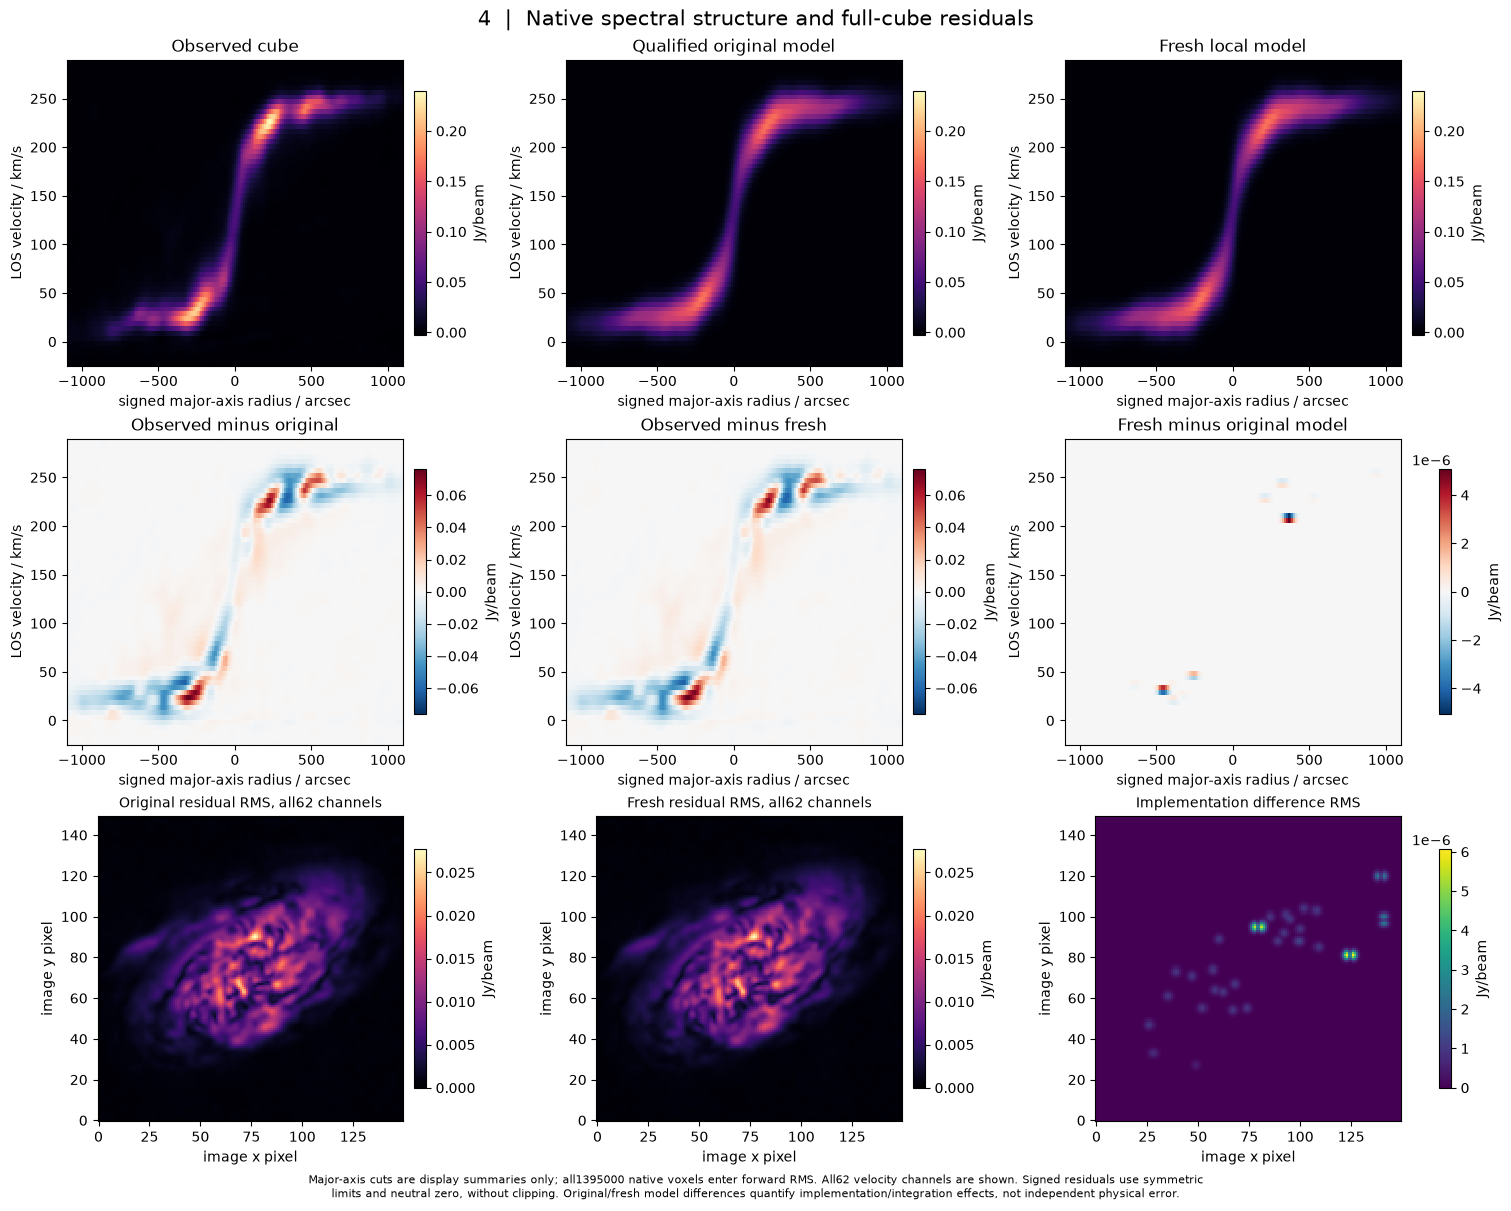

Observed-data forward RMS: original= 0.004572891456210505 fresh= 0.004572889593277305
Full-cube implementation difference RMS= 2.1037116319703152e-07


In [6]:
angle=float(np.median(fresh_fields[:,2]))
figure=viz.plot_residuals(cube,original_model,fresh_model,angle)
display(figure);plt.close(figure)
print('Observed-data forward RMS: original=',viz.rms(original_model.astype(float)-cube),'fresh=',viz.rms(fresh_model.astype(float)-cube))
print('Full-cube implementation difference RMS=',viz.rms(fresh_model.astype(float)-original_model))


The paper's task-relevant comparison between2D velocity-field information and3D spectral-cube fitting is retained here using the actual native initialization and final fit. The2D prepass has40 fitted rings; it is shown honestly with that support. The selected41-ring initialization also retains the source boundary starts. Both its emission prediction and the final emission prediction are actively evaluated, rather than substituting a cached model or zero image for a missing comparison.


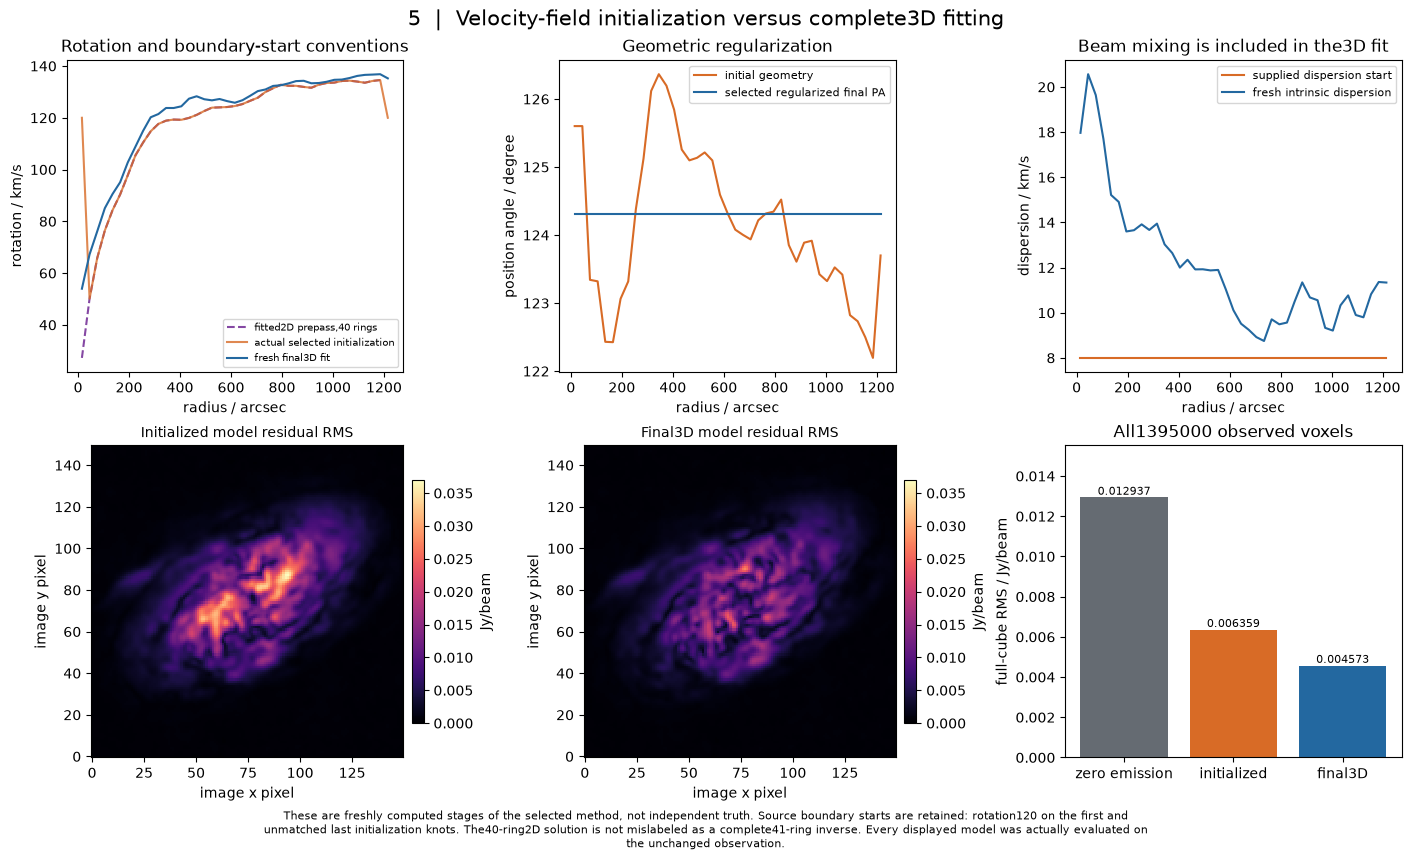

Fresh initialized-model full-cube RMS: 0.0063588017317435155


In [7]:
initial_model,initial_profile=full_model(cube,diagnostics['mask'],diagnostics['initial'])
figure=viz.plot_initialization(cube,diagnostics['initial'],diagnostics['prepass_parameters'],fresh_fields,initial_model,fresh_model)
display(figure);plt.close(figure)
print('Fresh initialized-model full-cube RMS:',viz.rms(initial_model.astype(float)-cube))


Finally, vary each physical field around the fresh solution while leaving the real observation unchanged. These are **forward sensitivity predictions**, not independently reoptimized reconstructions,new benchmark acquisitions or posterior intervals. Rotation varies by±5%,dispersion by±20%,and PA by±3degrees; all other fields stay fixed. The same observation-only nuisance-brightness estimator is used for each prediction.


rotation minus actual full-cube RMS: 0.005330060124723594


rotation plus actual full-cube RMS: 0.0050616337623435245


dispersion minus actual full-cube RMS: 0.005057115547304862


dispersion plus actual full-cube RMS: 0.004674813302507418


angle minus actual full-cube RMS: 0.005312524008548583


angle plus actual full-cube RMS: 0.004913491132036462


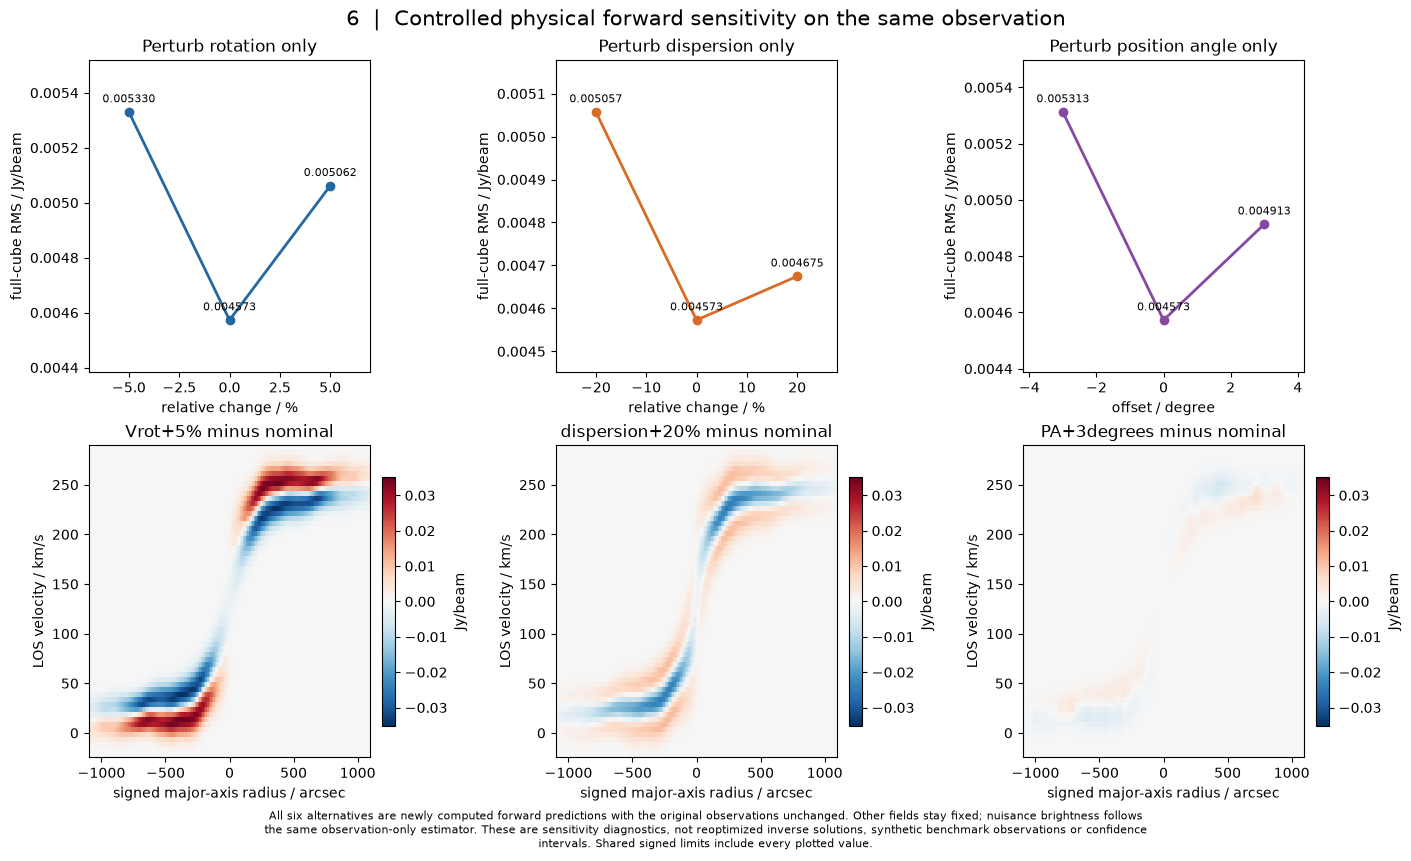

In [8]:
variants={}
for name,index,changes in [('rotation',0,[-.05,.05]),('dispersion',1,[-.2,.2]),('angle',2,[-3.,3.])]:
    for suffix,change in zip(['minus','plus'],changes):
        parameters=fresh_fields.copy()
        if index==2: parameters[:,index]+=change
        else: parameters[:,index]*=(1+change)
        predicted,_=full_model(cube,diagnostics['mask'],parameters)
        variants[name+'_'+suffix]=predicted
        print(name,suffix,'actual full-cube RMS:',viz.rms(predicted.astype(float)-cube),flush=True)
figure=viz.plot_sensitivity(cube,fresh_model,variants,angle)
display(figure);plt.close(figure)
np.savez_compressed(ROOT/'notebooks/reference_outputs/forward_sensitivity_measurements.npz',**{key:value[None] for key,value in variants.items()},initialized_model=initial_model[None])


## Conclusion

The complete selected inverse path actively fits every native annulus and returns all three physical profiles. The fresh output is independently scored for both per-quantity reference agreement and full-cube observation consistency. Operator stages,analytic derivatives,beam boundaries,random sampling distributions,standalone Judge edge cases and exact-source measurements provide complementary evidence; passing the Judge alone would not establish correctness.

The kinematic fields remain conditional on the fixed inclination,center,systemic velocity,vertical law,flux treatment and median angle regularization. Independent source seeds show nonzero reproducibility differences, especially in dispersion; the threshold is not a claim of high physical accuracy or posterior confidence. The supplied data are real reduced observations, not raw voltages. Data redistribution terms remain unresolved; code licensing does not automatically license the astronomical measurement.

The source baseline is the minimally qualified current implementation on this exact acquisition. Original undefined-memory runs and all corrections/failed extraction diagnostics remain in the private validation archive. No difficult output ring,comparison group or native residual voxel has been omitted to obtain a pass.
